
<div class="alert alert-block alert-success">
<b> Ex - 6 : </b> Convolutional AutoEncoders for Image Reconstruction

</div>

<hr style="border-top: 3px dotted #bbb;">


<details>
<summary><b>👉 Click here to reveal the hidden code solution</b></summary>

```python
# Your hidden code block sits neatly inside here
import tensorflow as tf
print("Hidden code executed!")
```
</details>


## Task 0 : Import Necessary Libraries

In [5]:

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

### Task 1: Load the Dataset

In [6]:
(x_train, _), (x_test, _) = mnist.load_data()


## Task 2: Preprocess the Data

In [7]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Add a channel dim(for grayscale imgs, it's 1 channel)
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

## Task 3 : Design the Convolutional AutoEncoder

In [27]:
# # Normally we can write like 

input_img = layers.Input(shape=(28,28,1))
x = layers.Conv2D(32, (3,3), activation='relu', padding='same')(input_img)
x = layers.MaxPooling2D((2,2), padding='same')(x)
x = layers.Conv2D(64, (2,2),padding='same')(x)
encoded = layers.MaxPooling2D((2,2), padding='same')(x)

# Decoder
x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(encoded)
x = layers.UpSampling2D((2, 2))(x)
x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(x)
x = layers.UpSampling2D((2, 2))(x)
decoded = layers.Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)
# Conv Autoencoder model
Convautoencoder = models.Model(input_img, decoded)


# Design the conv autoencoder model
# def create_autoencoder() :
#     # Encoder 
#     input_img = layers.Input(shape=(28,28,1))
#     x = layers.Conv2D(32, (3,3), activation='relu', padding='same')(input_img)
#     x = layers.MaxPooling2D((2,2), padding='same')(x)
#     x = layers.Conv2D(64, (2,2),padding='same')(x)
#     encoded = layers.MaxPooling2D((2,2), padding='same')(x)

#     # Decoder
#     x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(encoded)
#     x = layers.UpSampling2D((2, 2))(x)
#     x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(x)
#     x = layers.UpSampling2D((2, 2))(x)
#     decoded = layers.Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)

#     # Conv Autoencoder model
#     Convautoencoder = models.Model(input_img, decoded)
#     return autoencoder 



In [28]:
# Convautoencoder = create_autoencoder()

In [37]:
Convautoencoder.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 14, 14, 64)     │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_4 (UpSampling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_5 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 192,773 (753.02 KB)

 Trainable params: 64,257 (251.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 128,516 (502.02 KB)

## Task 5: Compile the Model

In [29]:
Convautoencoder.compile(
    optimizer=Adam(),
    loss='binary_crossentropy'
    )

## Task 6: Train the Model

In [30]:
history = Convautoencoder.fit(x_train, x_train,
                          epochs=50,
                          batch_size=256,
                          shuffle=True,
                          validation_data=(x_test, x_test))

Epoch 1/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 28s 110ms/step - loss: 0.1288 - val_loss: 0.0782
Epoch 2/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 26s 112ms/step - loss: 0.0758 - val_loss: 0.0728
Epoch 3/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 26s 112ms/step - loss: 0.0725 - val_loss: 0.0708
Epoch 4/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 24s 101ms/step - loss: 0.0709 - val_loss: 0.0695
Epoch 5/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 25s 105ms/step - loss: 0.0697 - val_loss: 0.0687
Epoch 6/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 25s 106ms/step - loss: 0.0689 - val_loss: 0.0679
Epoch 7/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 23s 97ms/step - loss: 0.0682 - val_loss: 0.0674
Epoch 8/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 23s 100ms/step - loss: 0.0676 - val_loss: 0.0668
Epoch 9/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 24s 104ms/step - loss: 0.0671 - val_loss: 0.0663
Epoch 10/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 23s 97ms/step - loss: 0.0667 - val_loss: 0.0660
Epoch 11/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 22s 95ms/step - loss: 0.0663 - val_loss: 0.0656
Epoch 12/50
235/235 ━━

## Task 7: # Plot training and validation loss

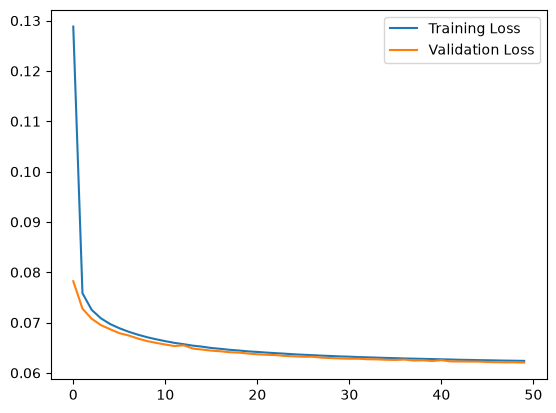

In [34]:
plt.plot(history.history['loss'],label='Training Loss')
plt.plot(history.history['val_loss'],label='Validation Loss')
plt.legend()
plt.show()

## Task 8: Encode and Decode some test imgs

In [35]:
decoded_imgs = autoencoder.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


# Task 9 : Display original and reconstructed images

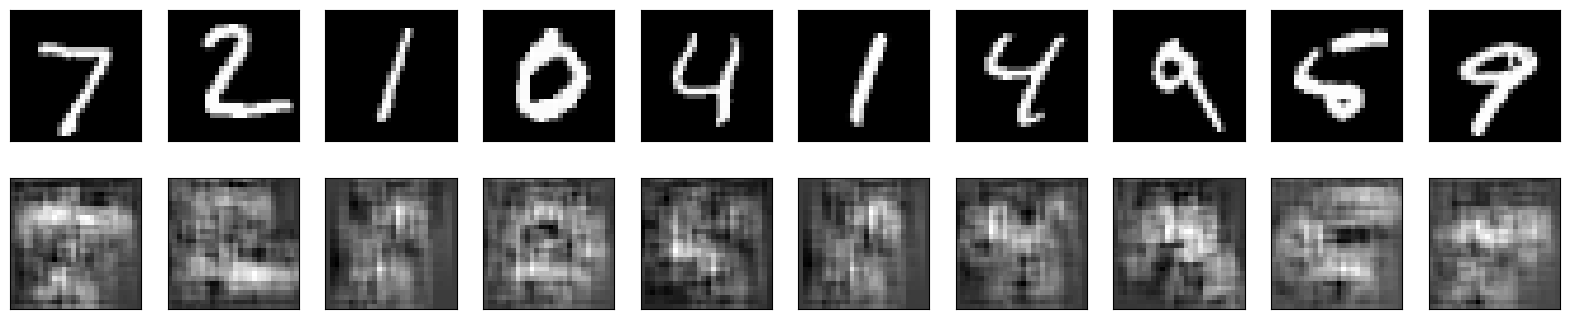

In [36]:
n = 10  # Number of images to display
plt.figure(figsize=(20, 4))
for i in range(n):
    # Display original
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Display reconstruction
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[i].reshape(28, 28), cmap='gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()